In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://api.slingacademy.com/v1/sample-data/files/student-scores.json"

response = requests.get(url, timeout=15)
response.raise_for_status()
data = response.json()

print("Data fetched successfully")
print("Number of records:", len(data))

Data fetched successfully
Number of records: 2000


In [3]:
df = pd.DataFrame(data)

print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
display(df.head())

Dataset shape: (2000, 17)
Available columns: ['id', 'first_name', 'last_name', 'email', 'gender', 'part_time_job', 'absence_days', 'extracurricular_activities', 'weekly_self_study_hours', 'career_aspiration', 'math_score', 'history_score', 'physics_score', 'chemistry_score', 'biology_score', 'english_score', 'geography_score']


,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76


In [ ]:
cleaned_df = df[["first_name", "last_name", "math_score"]].copy()

cleaned_df["student_name"] = (
    cleaned_df["first_name"].astype(str)
    + " "
    + cleaned_df["last_name"].astype(str)
)

cleaned_df["math_score"] = pd.to_numeric(
    cleaned_df["math_score"], errors="coerce"
)

cleaned_df = cleaned_df.dropna(subset=["math_score"])

cleaned_df = cleaned_df[["student_name", "math_score"]].reset_index(drop=True)

print("Data cleaning completed!")
print("Valid student records:", len(cleaned_df))
display(cleaned_df.head())

Data cleaning completed!
Valid student records: 2000


,student_name,math_score
0,Paul Casey,73
1,Danielle Sandoval,90
2,Tina Andrews,81
3,Tara Clark,71
4,Anthony Campos,84


In [7]:
average_score = cleaned_df["math_score"].mean()

print(f"Average math score: {average_score:.2f}")
print("Valid student records:", len(cleaned_df))

Average math score: 83.45
Valid student records: 2000


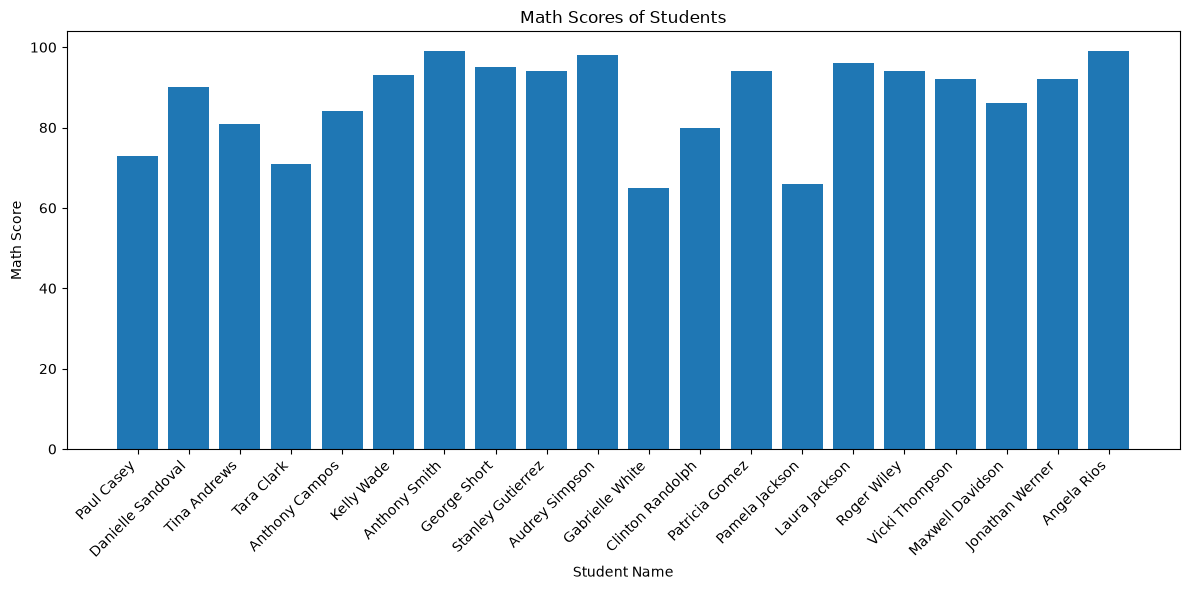

In [8]:
chart_df = cleaned_df.head(20)

plt.figure(figsize=(12, 6))
plt.bar(chart_df["student_name"], chart_df["math_score"])

plt.title("Math Scores of Students")
plt.xlabel("Student Name")
plt.ylabel("Math Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
print(f"Average score: {average_score:.2f}")
print(f"Students included: {len(cleaned_df)}")
display(cleaned_df.head())

Average score: 83.45
Students included: 2000


,student_name,math_score
0,Paul Casey,73
1,Danielle Sandoval,90
2,Tina Andrews,81
3,Tara Clark,71
4,Anthony Campos,84


In [11]:
print("Number of scores:", cleaned_df["math_score"].count())
print("Total of all math scores:", cleaned_df["math_score"].sum())
print("Average to 3 decimal places:", cleaned_df["math_score"].mean())
print("Average rounded to 2 decimals:", round(cleaned_df["math_score"].mean(), 2))

Number of scores: 2000
Total of all math scores: 166904
Average to 3 decimal places: 83.452
Average rounded to 2 decimals: 83.45
